In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/traffic.csv')

# Display the first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

First 5 rows of the dataset:


,event,date,country,city,artist,album,track,isrc,linkid
0,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
1,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
2,click,2021-08-21,India,Ludhiana,Reyanna Maria,So Pretty,So Pretty,USUM72100871,23199824-9cf5-4b98-942a-34965c3b0cc2
3,click,2021-08-21,France,Unknown,"Simone & Simaria, Sebastian Yatra",No Llores Más,No Llores Más,BRUM72003904,35573248-4e49-47c7-af80-08a960fa74cd
4,click,2021-08-21,Maldives,Malé,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8


In [ ]:
# Dataset overview
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include='all'))

Dataset Shape: (226278, 9)

Column Names:
['event', 'date', 'country', 'city', 'artist', 'album', 'track', 'isrc', 'linkid']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226278 entries, 0 to 226277
Data columns (total 9 columns):
 #   Column   Non-Null Count   Dtype 
---  ------   --------------   ----- 
 0   event    226278 non-null  object
 1   date     226278 non-null  object
 2   country  226267 non-null  object
 3   city     226267 non-null  object
 4   artist   226241 non-null  object
 5   album    226273 non-null  object
 6   track    226273 non-null  object
 7   isrc     219157 non-null  object
 8   linkid   226278 non-null  object
dtypes: object(9)
memory usage: 15.5+ MB

Missing Values:
event         0
date          0
country      11
city         11
artist       37
album         5
track         5
isrc       7121
linkid        0
dtype: int64

Duplicate Rows: 103711

Statistical Summary:


,event,date,country,city,artist,album,track,isrc,linkid
count,226278,226278,226267,226267,226241,226273,226273,219157,226278
unique,3,7,211,11993,2419,3254,3562,709,3839
top,pageview,2021-08-19,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
freq,142015,35361,47334,22791,40841,40841,40841,40841,40841


In [ ]:
# Create a copy of the dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Display missing values before handling them
print("Missing values before cleaning:")
print(df_clean.isnull().sum())

# Fill missing numerical values with the median
for col in df_clean.select_dtypes(include=np.number).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill missing categorical values with the mode
for col in df_clean.select_dtypes(include=['object', 'category']).columns:
    if df_clean[col].isnull().any():
        if not df_clean[col].mode().empty:
            df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned Dataset Shape:", df_clean.shape)

Missing values before cleaning:
event         0
date          0
country       5
city          5
artist       28
album         4
track         4
isrc       6306
linkid        0
dtype: int64

Missing values after cleaning:
event      0
date       0
country    0
city       0
artist     0
album      0
track      0
isrc       0
linkid     0
dtype: int64

Cleaned Dataset Shape: (122567, 9)


In [ ]:
# Select numerical columns
numeric_cols = df_clean.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(numeric_cols.tolist())

# Calculate mean, median and standard deviation
if len(numeric_cols) > 0:
    print("\nMean:")
    display(df_clean[numeric_cols].mean())

    print("\nMedian:")
    display(df_clean[numeric_cols].median())

    print("\nStandard Deviation:")
    display(df_clean[numeric_cols].std())

# Display the most frequent value in each column
print("\nMost Frequent Values (Mode):")
display(df_clean.mode().head(1))

Numerical Columns:
[]

Most Frequent Values (Mode):


,event,date,country,city,artist,album,track,isrc,linkid
0,pageview,2021-08-19,United States,Unknown,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8


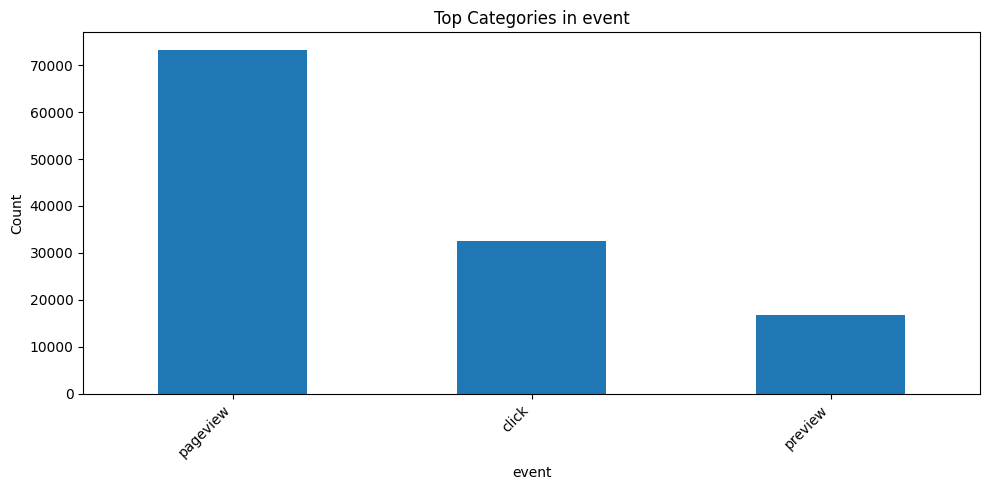

In [ ]:
# Select categorical columns
categorical_cols = df_clean.select_dtypes(
    include=['object', 'category']
).columns

if len(categorical_cols) > 0:
    col = categorical_cols[0]

    counts = df_clean[col].value_counts().head(10)

    plt.figure(figsize=(10, 5))
    counts.plot(kind='bar')

    plt.title(f'Top Categories in {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No categorical columns available for a bar chart.")

In [ ]:
numeric_cols = df_clean.select_dtypes(include=np.number).columns

if len(numeric_cols) > 0:
    col = numeric_cols[0]

    plt.figure(figsize=(8, 5))
    plt.hist(df_clean[col].dropna(), bins=20, edgecolor='black')

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()
else:
    print("No numerical columns available for a histogram.")

No numerical columns available for a histogram.


In [ ]:
numeric_cols = df_clean.select_dtypes(include=np.number).columns

if len(numeric_cols) >= 2:
    correlation = df_clean[numeric_cols].corr()

    plt.figure(figsize=(10, 6))
    sns.heatmap(
        correlation,
        annot=True,
        cmap='coolwarm',
        fmt='.2f'
    )

    plt.title('Correlation Heatmap')
    plt.tight_layout()
    plt.show()
else:
    print("At least two numerical columns are required for a correlation heatmap.")

At least two numerical columns are required for a correlation heatmap.


In [ ]:
numeric_cols = df_clean.select_dtypes(include=np.number).columns

for col in numeric_cols:
    print(f"\nTop 5 highest values in {col}:")
    display(df_clean.nlargest(min(5, len(df_clean)), col)[[col]])

In [ ]:
print("=" * 50)
print("WEBSITE TRAFFIC ANALYSIS SUMMARY")
print("=" * 50)

print("\n1. Total Records:", len(df_clean))
print("2. Total Columns:", len(df_clean.columns))
print("3. Duplicate Rows Remaining:", df_clean.duplicated().sum())

print("\n4. Numerical Columns:")
print(numeric_cols.tolist())

print("\n5. Categorical Columns:")
print(categorical_cols.tolist())

print("\n6. Average Values of Numerical Columns:")
if len(numeric_cols) > 0:
    display(df_clean[numeric_cols].mean())
else:
    print("No numerical columns available.")

print("\n7. Dataset Cleaning Completed.")
print("\nAnalysis summary generated successfully.")

WEBSITE TRAFFIC ANALYSIS SUMMARY

1. Total Records: 122567
2. Total Columns: 9
3. Duplicate Rows Remaining: 3

4. Numerical Columns:
[]

5. Categorical Columns:
['event', 'date', 'country', 'city', 'artist', 'album', 'track', 'isrc', 'linkid']

6. Average Values of Numerical Columns:
No numerical columns available.

7. Dataset Cleaning Completed.

Analysis summary generated successfully.


In [ ]:
# Clean the dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Convert date column into date format
df_clean['date'] = pd.to_datetime(
    df_clean['date'], errors='coerce'
)

# Display cleaned dataset details
print("Original records:", len(df))
print("Records after removing duplicates:", len(df_clean))
print("Duplicate rows remaining:", df_clean.duplicated().sum())

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDataset preview:")
display(df_clean.head())

print("\nEvent types:")
print(df_clean['event'].value_counts().head(10))

Original records: 226278
Records after removing duplicates: 122567
Duplicate rows remaining: 0

Missing values:
event         0
date          0
country       5
city          5
artist       28
album         4
track         4
isrc       6306
linkid        0
dtype: int64

Dataset preview:


,event,date,country,city,artist,album,track,isrc,linkid
0,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
2,click,2021-08-21,India,Ludhiana,Reyanna Maria,So Pretty,So Pretty,USUM72100871,23199824-9cf5-4b98-942a-34965c3b0cc2
3,click,2021-08-21,France,Unknown,"Simone & Simaria, Sebastian Yatra",No Llores Más,No Llores Más,BRUM72003904,35573248-4e49-47c7-af80-08a960fa74cd
4,click,2021-08-21,Maldives,Malé,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
5,click,2021-08-21,United States,Los Angeles,KenTheMan,I'm Perfect,I'm Perfect,US39N2102090,190c7170-4044-4c97-9709-926917155b02



Event types:
event
pageview    73360
click       32499
preview     16708
Name: count, dtype: int64


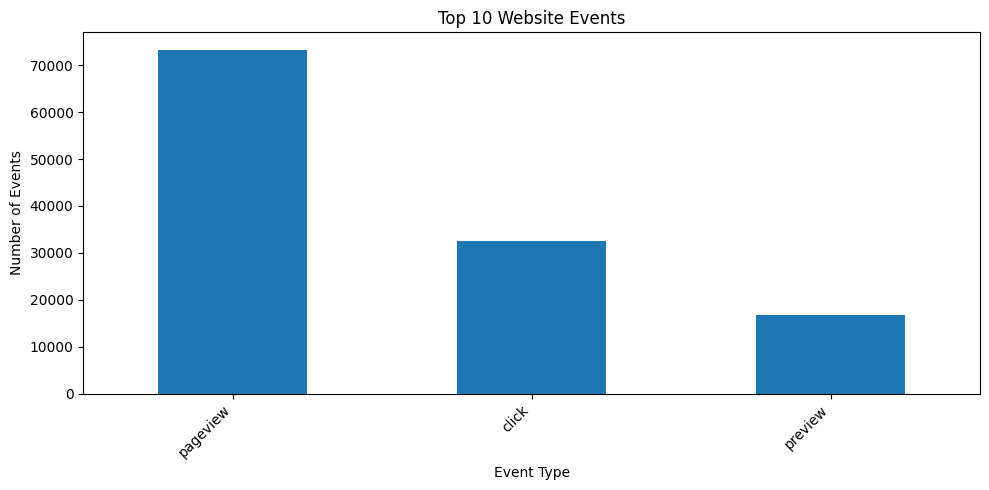

In [ ]:
plt.figure(figsize=(10, 5))

df_clean['event'].value_counts().head(10).plot(
    kind='bar'
)

plt.title('Top 10 Website Events')
plt.xlabel('Event Type')
plt.ylabel('Number of Events')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

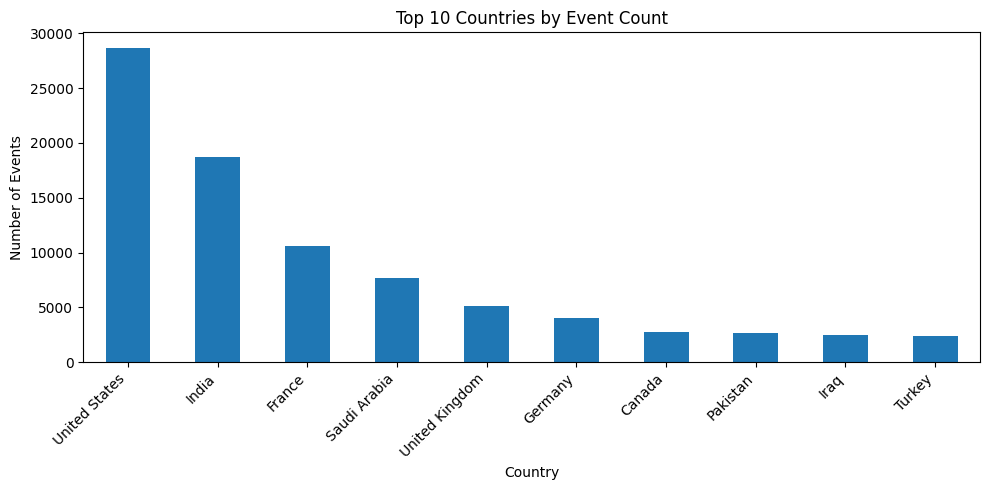

Top 10 countries:


,count
country,
United States,28664
India,18689
France,10565
Saudi Arabia,7682
United Kingdom,5095
Germany,4017
Canada,2784
Pakistan,2633
Iraq,2444


In [ ]:
country_counts = df_clean['country'].value_counts().head(10)

plt.figure(figsize=(10, 5))
country_counts.plot(kind='bar')

plt.title('Top 10 Countries by Event Count')
plt.xlabel('Country')
plt.ylabel('Number of Events')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("Top 10 countries:")
display(country_counts)

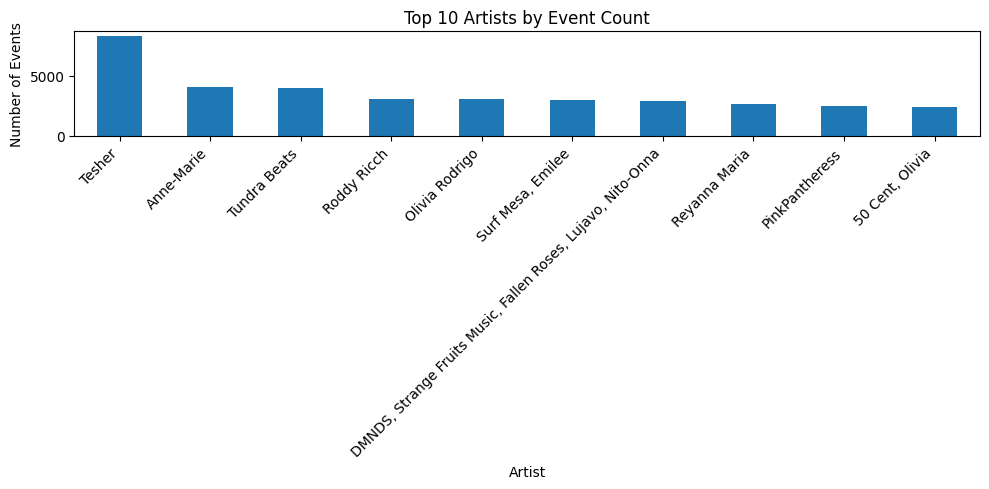

Top 10 artists:


,count
artist,
Tesher,8288
Anne-Marie,4029
Tundra Beats,3951
Roddy Ricch,3107
Olivia Rodrigo,3037
"Surf Mesa, Emilee",2956
"DMNDS, Strange Fruits Music, Fallen Roses, Lujavo, Nito-Onna",2865
Reyanna Maria,2675
PinkPantheress,2446


In [ ]:
artist_counts = df_clean['artist'].value_counts().head(10)

plt.figure(figsize=(10, 5))
artist_counts.plot(kind='bar')

plt.title('Top 10 Artists by Event Count')
plt.xlabel('Artist')
plt.ylabel('Number of Events')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("Top 10 artists:")
display(artist_counts)

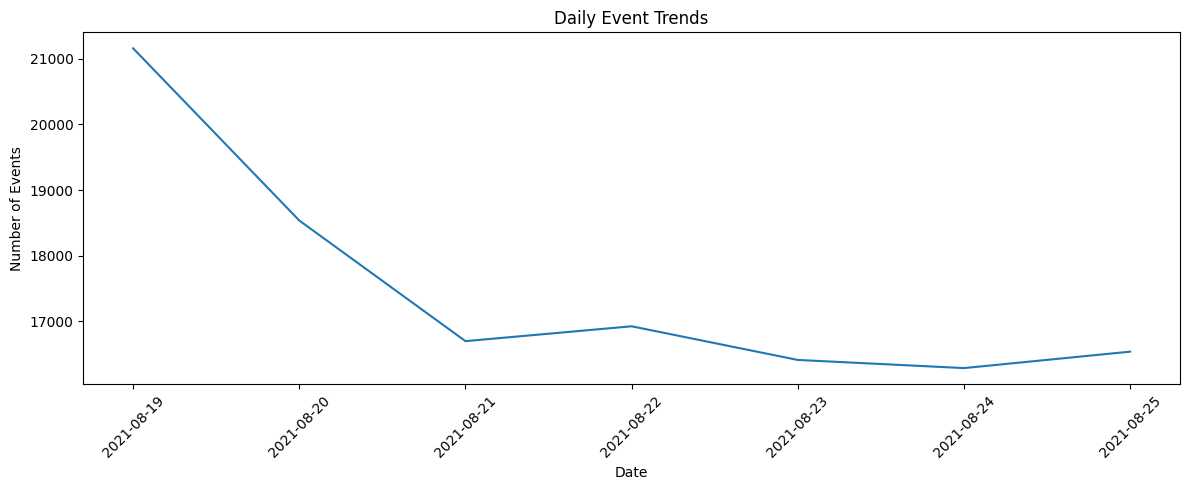

In [ ]:
daily_events = df_clean.dropna(subset=['date']).groupby(
    df_clean['date'].dropna().dt.date
).size()

plt.figure(figsize=(12, 5))
daily_events.plot()

plt.title('Daily Event Trends')
plt.xlabel('Date')
plt.ylabel('Number of Events')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
df_clean.to_csv(
    '/content/cleaned_traffic.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:

# FINAL INSIGHTS FROM THE DATASET

print("WEBSITE TRAFFIC ANALYSIS - KEY FINDINGS")
print("=" * 45)

print("\n1. Most frequent event:")
print(df_clean['event'].value_counts().head(1))

print("\n2. Top 5 countries:")
print(df_clean['country'].value_counts().head(5))

print("\n3. Top 5 artists:")
print(df_clean['artist'].value_counts().head(5))

print("\n4. Top 5 tracks:")
print(df_clean['track'].value_counts().head(5))

print("\n5. Date range:")
print("From:", df_clean['date'].min())
print("To:", df_clean['date'].max())

print("\n6. Records after cleaning:", len(df_clean))
print("7. Duplicate rows remaining:", df_clean.duplicated().sum())


WEBSITE TRAFFIC ANALYSIS - KEY FINDINGS

1. Most frequent event:
event
pageview    73360
Name: count, dtype: int64

2. Top 5 countries:
country
United States     28664
India             18689
France            10565
Saudi Arabia       7682
United Kingdom     5095
Name: count, dtype: int64

3. Top 5 artists:
artist
Tesher            8288
Anne-Marie        4029
Tundra Beats      3951
Roddy Ricch       3107
Olivia Rodrigo    3037
Name: count, dtype: int64

4. Top 5 tracks:
track
Jalebi Baby                             8288
Beautiful                               4037
Beautiful Day                           3951
Late At Night                           3059
ily (i love you baby) (feat. Emilee)    2956
Name: count, dtype: int64

5. Date range:
From: 2021-08-19 00:00:00
To: 2021-08-25 00:00:00

6. Records after cleaning: 122567
7. Duplicate rows remaining: 0
